> **Public copy.** The outputs below are from the original run on the private database. After that run, product, vendor and system names and release numbers in the code, text and tables were replaced with the public codes used everywhere in this repository (Vendor A to E; releases such as 1.51 and "Vendor C 3.0"), so every number is exactly as computed. The database itself is not published; the anonymised data files are in `data/`.


# 06 Time order and the train/test split

**Goal:** put every release in the order it was tested, check each test window, and split the releases by time: the model learns from the older releases and is tested on the newest ones.

**Why time order matters.** A random split would let the model learn from releases that happened *after* the ones it is tested on, which is peeking into the future. In real use, the QA team scores the next release using only past releases. So the test set must be the newest releases, and every component of a release stays on the same side of the split.

**What is checked here:**
1. **Order:** each release's test window (first and last tracker day), sorted by start date.
2. **Window quality:** the share of a release's text-confirmed defects that were raised inside its window (30 days either side). A low share means the window is incomplete or wrong.
3. **Size:** how much testing (person-days) and how many defects each release has.

Jagan checked the order and the flags by hand (`Hindsight_Release_Order_Check.xlsx`, 24 Nov 2026). His decisions are applied in section 3.

In [1]:
import sqlite3, sys
from pathlib import Path
import pandas as pd

# Works whether you run from the project folder or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
WORK = ROOT / 'data' / 'private' / 'hindsight_work.sqlite'    # Jira export (read only)
CLEAN = ROOT / 'data' / 'private' / 'hindsight_clean.sqlite'  # our cleaned tables
pd.set_option('display.width', 200)
print('Reading from:', CLEAN)
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
with sqlite3.connect(CLEAN) as cc:
    windows = pd.read_sql('select * from release_windows', cc, parse_dates=['window_start', 'window_end'])
    runs = pd.read_sql('select * from release_window_runs', cc, parse_dates=['run_start', 'run_end'])
    rel = pd.read_sql('select f.key, f.release_key, f.release_stream, f.vendor, f.work_type, f.final_confidence, '
                      'd.created, d.counts_for_risk from defect_release_final f join defects d using(key)', cc)
rel['created'] = pd.to_datetime(rel.created).dt.tz_localize(None)
FIRST_TRACKER_DAY = pd.Timestamp('2018-12-01')   # the trackers run from Dec 2018 ...
LAST_TRACKER_DAY = pd.Timestamp('2026-10-31')    # ... to Oct 2026
CUT = pd.Timestamp('2025-01-01')                 # train/test split agreed with Jagan (24 Nov 2026)
print(len(windows), 'releases have a tracker test window')

Reading from: data/private/hindsight_clean.sqlite


53 releases have a tracker test window


## 1. Every release in time order (tracker windows)

In [2]:
# Defects that count: release testing only (not upgrade work), and counted for risk (notebook 01)
counted = rel[(rel.work_type == 'release testing') & (rel.counts_for_risk == 1) & rel.release_key.notna()]
text = counted[counted.final_confidence.isin(['high', 'medium', 'low'])]

t = windows[['release_order', 'vendor', 'release_stream', 'release_key', 'vendor_release_no',
             'window_start', 'window_end', 'months']].copy()
allruns = runs.groupby('release_key').agg(runs=('run', 'nunique'), person_days=('person_days', 'sum'),
                                          last_run_end=('run_end', 'max'))
t = t.merge(allruns, on='release_key', how='left')
t['risk_defects'] = t.release_key.map(counted.groupby('release_key').size()).fillna(0).astype(int)
t['text_defects'] = t.release_key.map(text.groupby('release_key').size()).fillna(0).astype(int)

def window_check(table):
    """Share of text-confirmed defects raised inside / before each window (30 days either side)."""
    pad = pd.Timedelta(days=30)
    tx = text.merge(table[['release_key', 'window_start', 'window_end']], on='release_key')
    inside = (tx.created >= tx.window_start - pad) & (tx.created <= tx.window_end + pad)
    before = tx.created < tx.window_start - pad
    return (table.release_key.map(inside.groupby(tx.release_key).mean() * 100).round(),
            table.release_key.map(before.groupby(tx.release_key).mean() * 100).round())

t['inside_pct'], t['before_pct'] = window_check(t)
t = t.sort_values('release_order').reset_index(drop=True)
t[['release_order', 'vendor', 'release_key', 'window_start', 'window_end', 'runs', 'person_days',
   'risk_defects', 'text_defects', 'inside_pct']]

,release_order,vendor,release_key,window_start,window_end,runs,person_days,risk_defects,text_defects,inside_pct
0,1,Vendor A,1.37,2018-12-05,2018-12-31,3,70.000,77,75,4.0
1,2,Vendor A,1.39,2019-04-01,2019-12-31,2,279.500,204,191,95.0
2,3,Vendor C,Vendor C 3.0,2019-04-29,2019-08-01,1,5.125,70,60,0.0
3,4,Vendor B,CI 2,2019-07-22,2019-08-30,1,35.000,18,18,83.0
4,5,Vendor C,Vendor C 4.0,2019-10-01,2020-01-24,1,57.000,19,13,46.0
5,6,Vendor A,1.41,2020-01-13,2020-04-30,2,105.750,73,58,64.0
6,7,Vendor B,CI 3,2020-03-02,2020-11-11,2,39.000,31,25,80.0
7,8,Vendor C,Vendor C 4.1,2020-05-01,2020-07-23,1,31.750,22,0,NaN
8,9,Vendor C,Vendor C 4.2,2020-08-03,2020-11-30,1,38.500,35,7,100.0
9,10,Vendor E,Vendor E 6.0,2020-08-18,2020-11-12,1,3.000,3,0,NaN


## 2. Flags (what Jagan was asked to check)

- **Effort incomplete:** half or more of the release's named defects were raised before its tracker window, so its testing began before the trackers record it.
- **Small:** under 5 person-days or under 3 defects.
- The other flags are for checking only: a window that misses many named defects, no Jira defect naming the release, a very long window, several separate test runs (effort adds up all runs), or a release still running when the trackers end.

In [3]:
def flags(r):
    f = []
    if (r.before_pct or 0) >= 50:
        f.append('effort incomplete: testing began before the tracker window')
    elif r.text_defects >= 5 and r.inside_pct < 60:
        f.append(f'window misses many named defects ({r.inside_pct:.0f}% inside)')
    if r.person_days < 5 or r.risk_defects < 3:
        f.append('small: under 5 person-days or under 3 defects')
    if r.release_stream in ('Vendor A', 'Vendor B') and r.text_defects == 0:
        f.append('no Jira defect names this release')
    if r.months > 9:
        f.append(f'long window ({r.months} months)')
    if r.runs > 1:
        f.append(f'{r.runs} separate test runs (effort adds them all)')
    if r.last_run_end >= LAST_TRACKER_DAY - pd.Timedelta(days=10):
        f.append('may still be running when the trackers end (Oct 2026)')
    return '; '.join(f)

t['check_flags'] = t.apply(flags, axis=1)
t[t['check_flags'] != ''][['release_key', 'person_days', 'risk_defects', 'inside_pct', 'check_flags']]

,release_key,person_days,risk_defects,inside_pct,check_flags
0,1.37,70.000,77,4.0,effort incomplete: testing began before the tr...
1,1.39,279.500,204,95.0,2 separate test runs (effort adds them all)
2,Vendor C 3.0,5.125,70,0.0,effort incomplete: testing began before the tr...
4,Vendor C 4.0,57.000,19,46.0,effort incomplete: testing began before the tr...
5,1.41,105.750,73,64.0,2 separate test runs (effort adds them all)
6,CI 3,39.000,31,80.0,2 separate test runs (effort adds them all)
9,Vendor E 6.0,3.000,3,NaN,small: under 5 person-days or under 3 defects
10,CI 4,50.250,43,91.0,2 separate test runs (effort adds them all)
11,1.42,185.500,45,91.0,2 separate test runs (effort adds them all)
13,CI 5,52.000,19,56.0,window misses many named defects (56% inside)


## 3. Jagan's decisions (24 Nov 2026)

| Release(s) | Decision | Reason |
| --- | --- | --- |
| Small vendor releases (Vendor E 6.0, Vendor E 8.0, Vendor E 8.2, Vendor C 5.3, Vendor D v2.24, v2.25, v2.29, CI 11.4) | In the model | Vendor releases are naturally small. The label's rule of at least 2 defects stops one stray defect from making a hotspot. |
| Vendor D regression 2023 | Not in the model | A one-day regression run with no defects |
| 1.37, Vendor C 3.0, Vendor C 4.0 | In the model, window from the tracker **and** the defects | Their testing began before the tracker recorded it. The window runs from the earlier of the tracker start and the defects' start to the later of the tracker end and the defects' end, ignoring the few stray defects at each end (outside the middle 90%). |
| 1.37, Vendor C 3.0 | Effort estimated | Their tracker effort misses most of their testing (Vendor C 3.0: 5 person-days against 70 defects). Each gets the typical effort (median person-days) of its vendor's training releases with full effort, and is flagged. The model step runs with and without these two. |
| Vendor C 4.0 | Own tracker effort | Its 57 person-days give a normal rate (about 3 defects per 10 person-days). |
| 1.28 to 1.36 | History and dashboard only | Tested before the trackers, so no effort. Their defects count in the history of later releases, with windows taken from their defects. The stray mentions 1.35 (one defect in 2020) and CI 1 (one defect in 2024) get no window. |
| 1.55, 1.56 | Kept as they are | 1.55 is a real release; 1.56 testing has finished. |

In [4]:
OUT_OF_MODEL = ['Vendor D regression 2023']
DATES_FROM_DEFECTS = ['1.37', 'Vendor C 3.0', 'Vendor C 4.0']
EFFORT_ESTIMATED = ['1.37', 'Vendor C 3.0']
STRAYS = ['1.35', 'CI 1']

# The middle 90% of each release's defect dates
spread = counted.groupby('release_key').created.quantile([0.05, 0.95]).unstack()
spread.columns = ['p05', 'p95']

t['tracker_start'], t['tracker_end'] = t.window_start, t.window_end
for k in DATES_FROM_DEFECTS:
    i = t.index[t.release_key == k][0]
    t.loc[i, 'window_start'] = min(t.loc[i, 'tracker_start'], spread.loc[k, 'p05'].normalize())
    t.loc[i, 'window_end'] = max(t.loc[i, 'tracker_end'], spread.loc[k, 'p95'].normalize())
t['dates_from'] = np.where(t.release_key.isin(DATES_FROM_DEFECTS), 'tracker and defects', 'tracker')
t['months'] = np.where(t.release_key.isin(DATES_FROM_DEFECTS),
                       (t.window_end.dt.year - t.window_start.dt.year) * 12 + t.window_end.dt.month - t.window_start.dt.month + 1,
                       t.months)

t['in_model'] = ~t.release_key.isin(OUT_OF_MODEL)
t['person_days_tracker'] = t.person_days
t['effort_estimated'] = t.release_key.isin(EFFORT_ESTIMATED)
typical = t[t.in_model & ~t.effort_estimated & (t.window_start < CUT)].groupby('vendor').person_days.median()
t.loc[t.effort_estimated, 'person_days'] = t.loc[t.effort_estimated, 'vendor'].map(typical)

t['inside_pct'], t['before_pct'] = window_check(t)       # re-checked with the final windows
t['source'] = 'tracker'
print('Typical effort of training releases (median person-days):', typical.round(1).to_dict())
changed = t[t.release_key.isin(DATES_FROM_DEFECTS)]
changed[['release_key', 'tracker_start', 'tracker_end', 'window_start', 'window_end', 'person_days_tracker',
         'person_days', 'effort_estimated', 'risk_defects', 'inside_pct']]

Typical effort of training releases (median person-days): {'Vendor A': 105.0, 'Vendor B': 66.0, 'Vendor C': 38.5, 'Vendor E': 7.4}


,release_key,tracker_start,tracker_end,window_start,window_end,person_days_tracker,person_days,effort_estimated,risk_defects,inside_pct
0,1.37,2018-12-05,2018-12-31,2018-04-05,2019-07-06,70.000,105.0,True,77,96.0
2,Vendor C 3.0,2019-04-29,2019-08-01,2018-04-18,2019-10-30,5.125,38.5,True,70,93.0
4,Vendor C 4.0,2019-10-01,2020-01-24,2019-07-19,2020-01-24,57.000,57.0,False,19,100.0


## 4. Releases from before the trackers (history and dashboard only)

These releases were tested before the trackers start (Dec 2018), so there is no effort figure for them. They are not training rows, but their defects count in the history of later releases, using windows taken from their defect dates (the middle 90%). The two stray mentions get no window.

In [5]:
jira_only = (counted[~counted.release_key.isin(windows.release_key)]
             .groupby(['release_key', 'release_stream'])
             .agg(defects=('key', 'size'), first_defect=('created', 'min'), last_defect=('created', 'max'))
             .reset_index().sort_values('first_defect'))

old = counted[~counted.release_key.isin(windows.release_key) & ~counted.release_key.isin(STRAYS)]
history_rows = (old.groupby(['release_key', 'release_stream', 'vendor'])
                .agg(risk_defects=('key', 'size'),
                     window_start=('created', lambda s: s.quantile(0.05).normalize()),
                     window_end=('created', lambda s: s.quantile(0.95).normalize()))
                .reset_index())
history_rows['text_defects'] = history_rows.release_key.map(text.groupby('release_key').size()).fillna(0).astype(int)
history_rows = history_rows.assign(in_model=False, source='Jira only (history)', dates_from='defects',
                                   effort_estimated=False,
                                   check_flags='before the trackers: history and dashboard only')
jira_only

,release_key,release_stream,defects,first_defect,last_defect
0,1.28,Vendor A,1,2016-08-19 13:57:24,2016-08-19 13:57:24
3,1.31,Vendor A,4,2016-08-19 15:25:38,2016-11-25 17:10:53
5,1.33,Vendor A,62,2016-08-19 16:11:43,2016-11-25 17:30:34
1,1.29,Vendor A,6,2016-08-19 16:13:36,2016-08-19 16:20:40
4,1.32,Vendor A,4,2016-08-22 09:41:50,2016-11-25 17:16:38
6,1.34,Vendor A,66,2016-08-22 11:01:55,2017-10-30 17:22:04
2,1.30,Vendor A,1,2016-11-25 17:12:03,2016-11-25 17:12:03
8,1.36,Vendor A,54,2017-12-13 17:05:30,2019-02-14 11:58:19
7,1.35,Vendor A,1,2020-03-13 17:30:36,2020-03-13 17:30:36
9,CI 1,Vendor B,1,2024-08-05 14:28:54,2024-08-05 14:28:54


In [6]:
t = pd.concat([t, history_rows], ignore_index=True)
t = t.sort_values(['window_start', 'release_key']).reset_index(drop=True)
t['tracker_order'] = t.release_order
t['release_order'] = np.arange(1, len(t) + 1)          # order by start date, after Jagan's changes
print(len(t), 'releases in the timeline:', int(t.in_model.sum()), 'in the model,', int((~t.in_model).sum()), 'history only')

61 releases in the timeline: 52 in the model, 9 history only


## 5. The split: learn from the past, test on the newest releases

**Rule:** releases that started testing before **1 January 2025** are the training set; releases that started on or after it are the test set. All components of a release stay on the same side.

In [7]:
t['split'] = np.where(~t.in_model, 'history only', np.where(t.window_start < CUT, 'train', 'test'))
print(t.split.value_counts().to_string(), end='\n\n')
print(t[t.in_model].groupby(['split', 'vendor']).size().unstack(fill_value=0), end='\n\n')
model = t[t.in_model]
print(f"Training: {model[model.split == 'train'].window_start.min():%b %Y} to {model[model.split == 'train'].window_start.max():%b %Y} starts; "
      f"test: {model[model.split == 'test'].window_start.min():%b %Y} to {model[model.split == 'test'].window_start.max():%b %Y} starts")
share = model[model.split == 'test'].risk_defects.sum() / model.risk_defects.sum()
print(f'The test set holds {share:.0%} of the defects in the model.')

split
train           36
test            16
history only     9

vendor  Vendor A  Vendor B  Vendor C  Vendor D  Vendor E
split                                                   
test           6         4         2         3         1
train         12        10        10         0         4

Training: Apr 2018 to Dec 2024 starts; test: Jan 2025 to Aug 2026 starts
The test set holds 15% of the defects in the model.


Some training releases were still being tested after the cut (they started before it). The model step adds a stricter check, **walk-forward**: each test release is predicted only from releases that had finished before it started.

In [8]:
t[(t.split == 'train') & (t.last_run_end >= CUT)][['release_key', 'window_start', 'last_run_end']]

,release_key,window_start,last_run_end
41,1.48,2024-05-20,2025-05-23
42,1.49,2024-09-18,2025-01-15
43,1.50,2024-11-26,2025-06-27
44,CI 11,2024-12-12,2025-08-15


## 6. The timeline

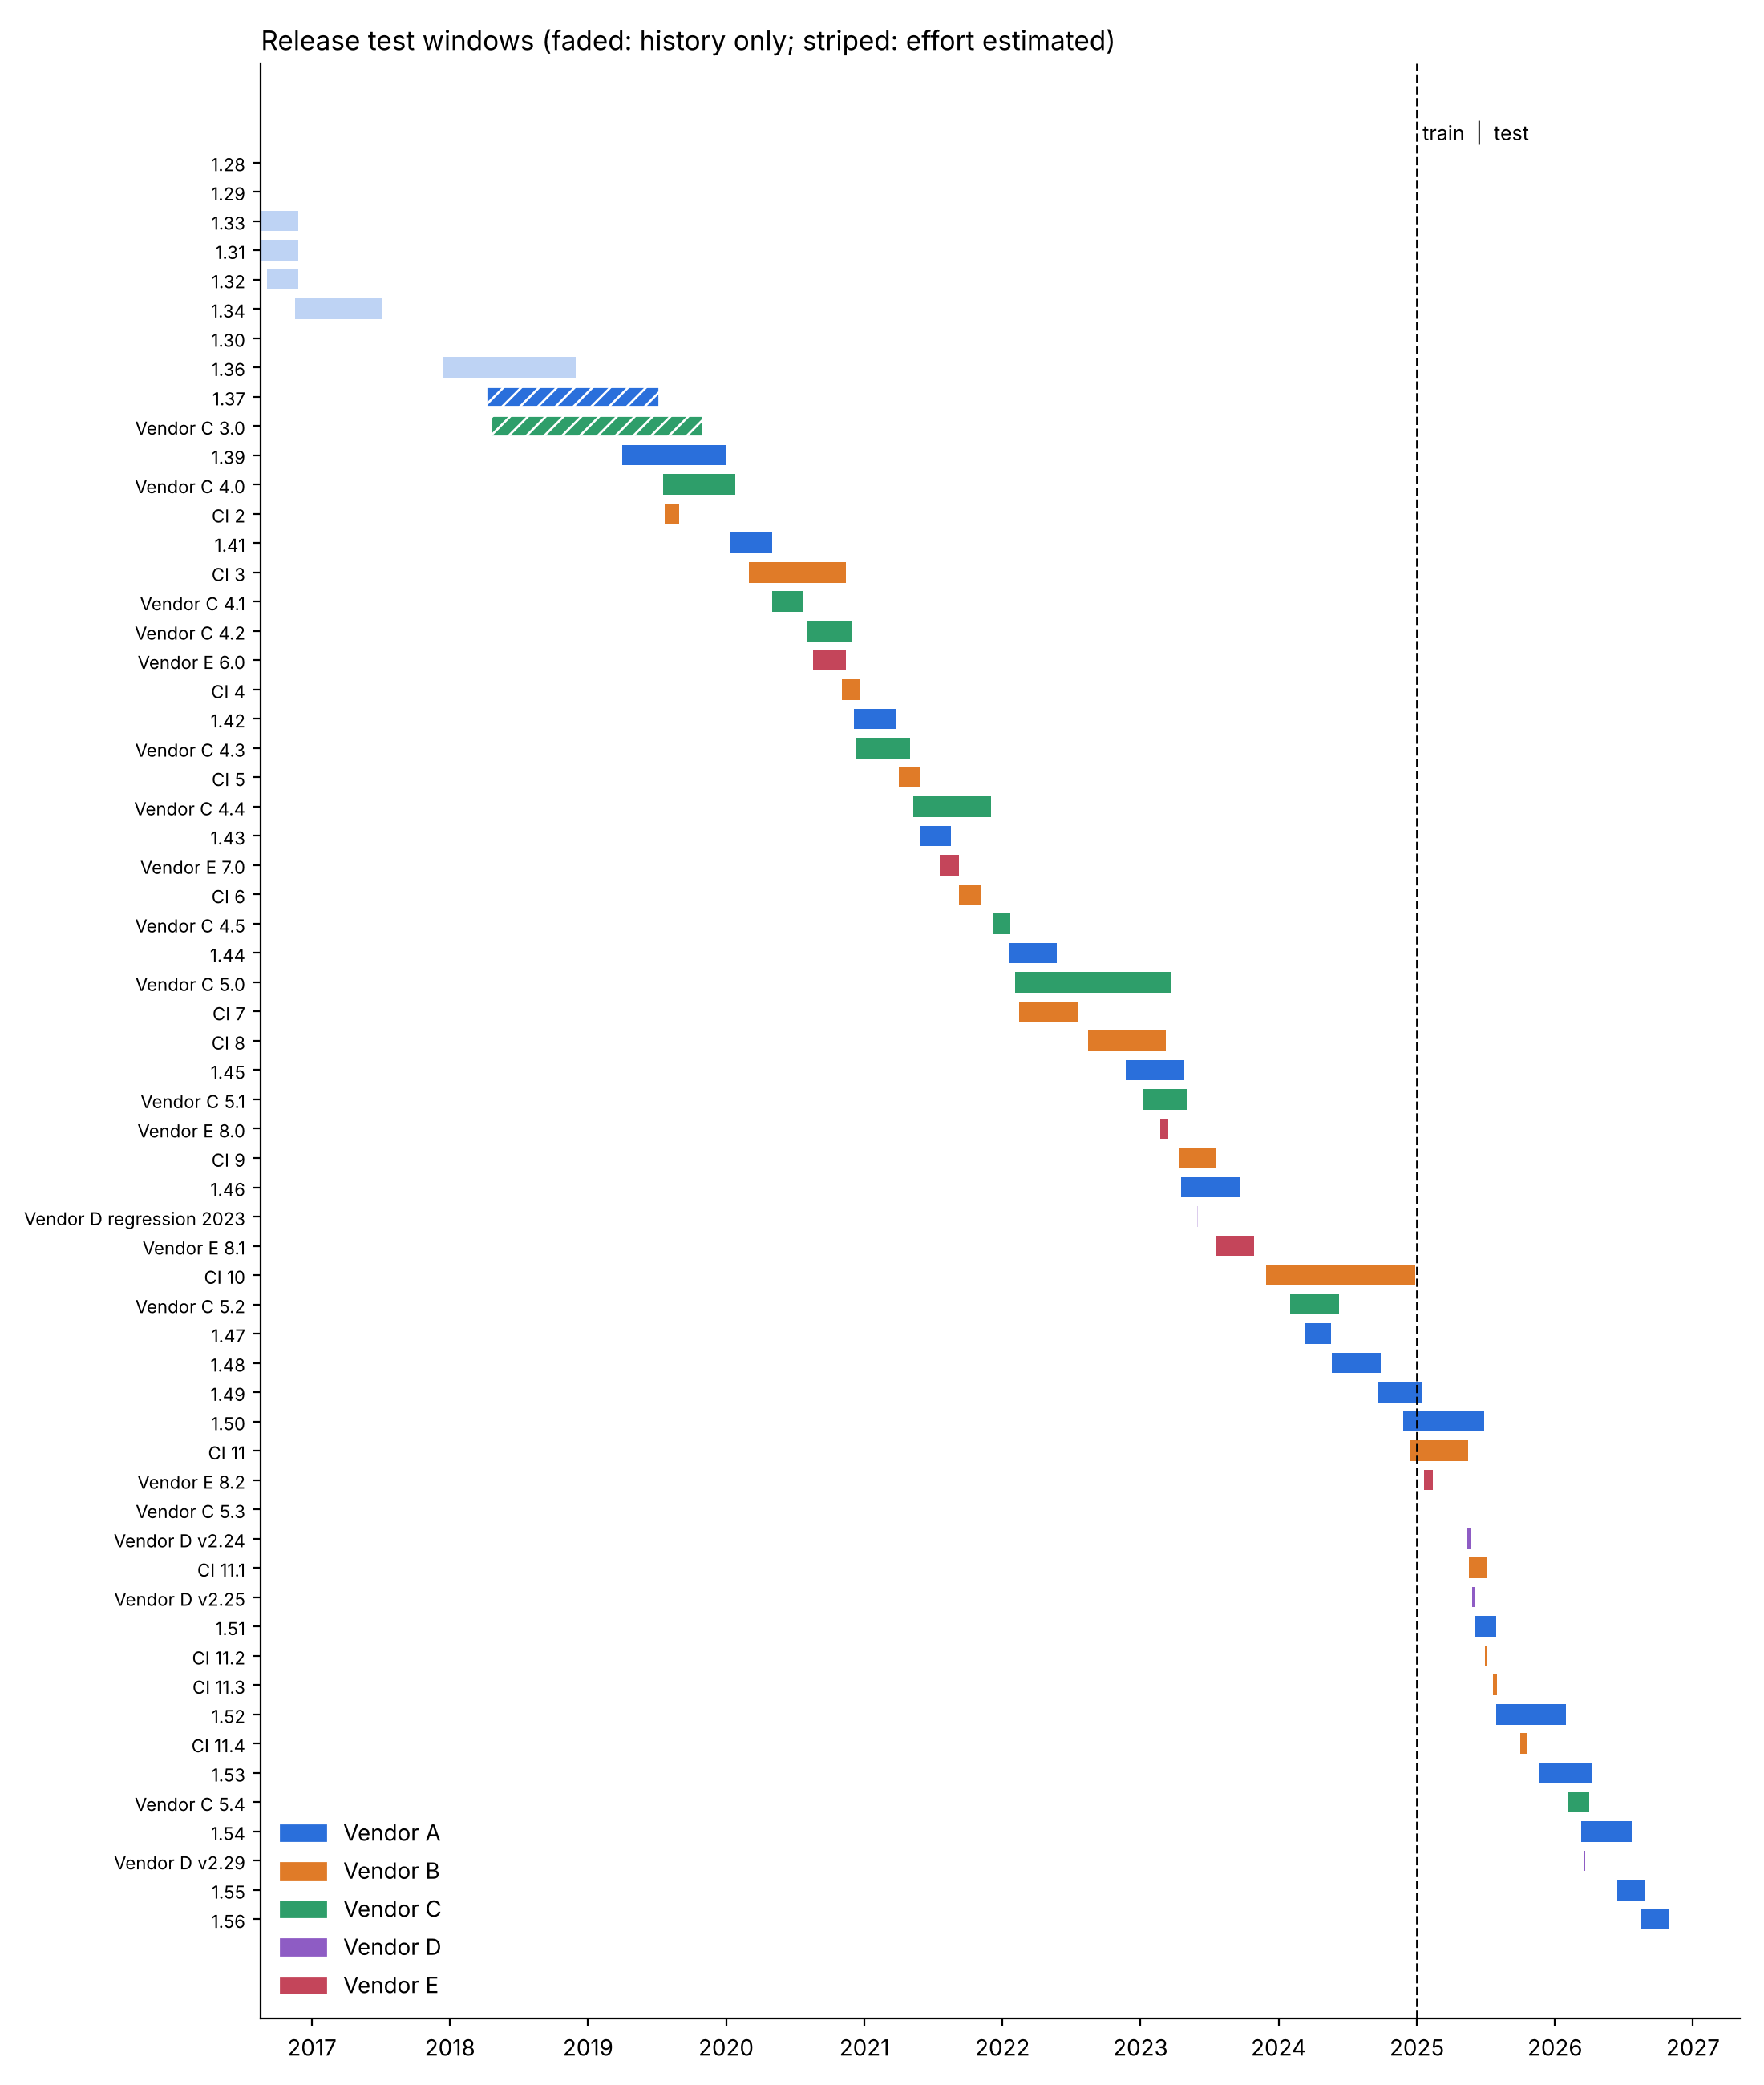

In [9]:
colors = {'Vendor A': '#2a6fdb', 'Vendor B': '#e07b28', 'Vendor C': '#2e9e6a', 'Vendor D': '#8e5cc4', 'Vendor E': '#c4455a'}
g = t.sort_values('window_start', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 13))
for i, r in g.iterrows():
    ax.barh(i, (r.window_end - r.window_start).days + 1, left=r.window_start, height=0.7,
            color=colors.get(r.vendor, 'grey'), alpha=1.0 if r.in_model else 0.3,
            hatch='///' if r.effort_estimated else None, edgecolor='white' if r.effort_estimated else None)
ax.set_yticks(range(len(g)))
ax.set_yticklabels(g.release_key, fontsize=8)
ax.axvline(CUT, color='black', linestyle='--', linewidth=1)
ax.text(CUT, len(g) - 0.4, ' train  |  test', fontsize=9, va='bottom')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], colors.keys(), loc='lower left', frameon=False)
ax.set_title('Release test windows (faded: history only; striped: effort estimated)', loc='left')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
(ROOT / 'reports').mkdir(exist_ok=True)
plt.savefig(ROOT / 'reports' / 'release_timeline.png', dpi=150)
plt.show()

## 7. Save

In [10]:
with sqlite3.connect(CLEAN) as cc:
    t.to_sql('release_timeline', cc, if_exists='replace', index=False)
    jira_only.to_sql('releases_before_trackers', cc, if_exists='replace', index=False)
print('saved', len(t), 'releases in the timeline (', int(t.in_model.sum()), 'in the model ) and',
      len(jira_only), 'releases named in Jira without a tracker window')

saved 61 releases in the timeline ( 52 in the model ) and 10 releases named in Jira without a tracker window


## What is next

Notebook 07 builds the fact table: one row per component and release, with the defects found and the history known before each release started.